# Modelo de demanda: salidas por estación y hora

**Problema:** regresión supervisada. Predecir cuántas bicis salen de cada estación en cada hora.

**Qué compara este notebook** (mismo conjunto de prueba, mismas métricas):

| Tipo | Modelo |
| --- | --- |
| Referencias simples | Promedio histórico · Semana pasada · Media de 4 semanas |
| Visto en clase | Regresión lineal · Perceptrón multicapa (MLP) |
| Modelo avanzado | XGBoost global |

**Cómo correrlo:** Restart & Run All, con `RAPIDO = True` para validar que todo funciona (unos minutos) y después `RAPIDO = False` para la corrida final que se reporta. Requiere `trips_clean.parquet` (`python src/ingest.py`) y `pip install -r requirements.txt`.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import modelo as M

# True: corrida corta para validar (menos combinaciones, menos filas, menos épocas)
# False: corrida final para reportar (tarda bastante más y calienta la compu)
RAPIDO = False

N_ITER = 4 if RAPIDO else 12                       # combinaciones de hiperparámetros de XGBoost
MLP_FILAS = 500_000 if RAPIDO else 1_500_000       # filas con las que entrena el MLP
MLP_EPOCAS = 6 if RAPIDO else 15

## 1. Tratamiento de datos

- Se usan los viajes de 1 a 45 minutos desde el 1 de marzo de 2026 y con estación de origen conocida.
- La tabla es **estación × fecha × hora**, e incluye las horas sin viajes con `salidas = 0`, para que el modelo aprenda también cuándo no hay demanda. Cada estación se considera activa entre su primer y su último viaje.
- **Variables de contexto reciente** (con 7 días o más de rezago): `lag_7d` (lo que salió hace una semana a esa hora), `media_4sem` (promedio de las últimas 4 semanas para ese día y hora) y `nivel_semana` (demanda por hora de la estación hace una a dos semanas). Sirven para detectar cambios de nivel como las vacaciones de verano. Se descartan las filas sin esa historia (primera semana de cada estación).

In [2]:
validos = M.cargar_validos()
estaciones = M.cargar_estaciones()
tabla = M.construir_tabla(validos, estaciones)

print(f"Viajes usados: {len(validos):,}")
print(f"Filas de la tabla (estación-fecha-hora): {len(tabla):,}")
print(f"Estaciones: {tabla['estacion'].nunique()} | Días: {tabla['fecha'].nunique()}")
print(f"% de filas con cero salidas: {(tabla['salidas'] == 0).mean():.1%}")
print(f"Salidas por estación-hora: media {tabla['salidas'].mean():.2f}, máx {tabla['salidas'].max()}")
tabla.head()

Viajes usados: 9,159,620
Filas de la tabla (estación-fecha-hora): 2,842,368
Estaciones: 678 | Días: 175
% de filas con cero salidas: 35.4%
Salidas por estación-hora: media 3.06, máx 198


,estacion,fecha,hora,salidas,dia_semana,es_fin_de_semana,lat,lon,capacidad,cp,alcaldia,lag_7d,media_4sem,nivel_semana
0,1,2026-03-10,0,0,1,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,0.0,0.0,9.083333
1,1,2026-03-10,1,0,1,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,0.0,0.0,9.083333
2,1,2026-03-10,2,0,1,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,0.0,0.0,9.083333
3,1,2026-03-10,3,0,1,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,0.0,0.0,9.083333
4,1,2026-03-10,4,0,1,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,0.0,0.0,9.083333


## 2. Partición entrenamiento / prueba

Por fechas, no al azar: se entrena con el pasado y se prueba con el futuro. Una partición aleatoria mezclaría horas del mismo día en ambos lados y filtraría información. Los hiperparámetros se eligen con una validación tomada de los últimos días de entrenamiento; la prueba se usa solo al final.

In [3]:
train, test, corte = M.split_por_fechas(tabla, frac_train=0.8)
print(f"Corte: {corte.date()}")
print(f"Train: {train['fecha'].min().date()} a {train['fecha'].max().date()} ({len(train):,} filas)")
print(f"Test:  {test['fecha'].min().date()} a {test['fecha'].max().date()} ({len(test):,} filas)")
print(f"Salidas promedio por estación-hora: train {train['salidas'].mean():.2f} | test {test['salidas'].mean():.2f}")

Corte: 2026-07-28
Train: 2026-03-10 a 2026-07-27 (2,275,296 filas)
Test:  2026-07-28 a 2026-08-31 (567,072 filas)
Salidas promedio por estación-hora: train 3.09 | test 2.92


## 3. Referencias simples (baselines)

Reglas sin aprendizaje que el modelo debe superar:

- **Promedio histórico:** promedio de train por estación, hora y tipo de día (entre semana / fin de semana).
- **Semana pasada:** lo que pasó hace 7 días en esa estación y hora.
- **Media de 4 semanas:** promedio de las 4 semanas previas para esa estación, hora y día de la semana.

In [4]:
y_test = test[M.TARGET].to_numpy()
preds = {
    "Promedio histórico": M.baseline_promedio(train, test),
    "Semana pasada": M.baseline_semana_pasada(test),
    "Media 4 semanas": M.baseline_media_4sem(test),
}
pd.DataFrame({k: M.metricas(y_test, v) for k, v in preds.items()}).T.round(3)

,RMSE,MAE,Sesgo
Promedio histórico,2.559,1.448,0.171
Semana pasada,3.055,1.747,-0.019
Media 4 semanas,2.494,1.449,-0.028


## 4. Regresión lineal

Mínimos cuadrados sobre variables **escaladas**: one-hot para estación, hora y día de la semana, y estandarización (z-score) para latitud, longitud, capacidad y las variables de rezago. Los valores faltantes (estaciones sin coordenadas) se imputan con la mediana.

In [5]:
lineal = M.entrenar_lineal(train)
preds["Regresión lineal"] = lineal.predict(test)
print({k: round(v, 3) for k, v in M.metricas(y_test, preds["Regresión lineal"]).items()})

{'RMSE': 2.453, 'MAE': 1.466, 'Sesgo': 0.043}


## 5. Perceptrón multicapa (MLP)

| Elemento | Valor |
| --- | --- |
| Entrada | ~720 variables: one-hot de estación (677), hora (24) y día de la semana (7); z-score de latitud, longitud, capacidad y 3 rezagos; fin de semana |
| Capas ocultas | 2: 64 y 32 neuronas |
| Activación | ReLU (salida lineal, 1 neurona) |
| Pérdida | Error cuadrático medio (MSE) |
| Optimizador | Adam, `learning_rate = 0.001`, lotes de 2048 |
| Regularización | *Early stopping*: se detiene si el RMSE de validación no mejora en 3 épocas |

La curva de aprendizaje muestra el RMSE de entrenamiento y de validación por época: si el de entrenamiento baja y el de validación sube, hay sobreajuste.

época  1  RMSE train=2.558  RMSE val=2.498
época  2  RMSE train=2.515  RMSE val=2.465
época  3  RMSE train=2.489  RMSE val=2.452
época  4  RMSE train=2.472  RMSE val=2.446
época  5  RMSE train=2.461  RMSE val=2.444
época  6  RMSE train=2.452  RMSE val=2.443
época  7  RMSE train=2.446  RMSE val=2.443
época  8  RMSE train=2.441  RMSE val=2.442
época  9  RMSE train=2.437  RMSE val=2.440
época 10  RMSE train=2.433  RMSE val=2.439
época 11  RMSE train=2.430  RMSE val=2.440
época 12  RMSE train=2.426  RMSE val=2.441
época 13  RMSE train=2.423  RMSE val=2.441
early stopping
{'RMSE': 2.419, 'MAE': 1.396, 'Sesgo': 0.04}


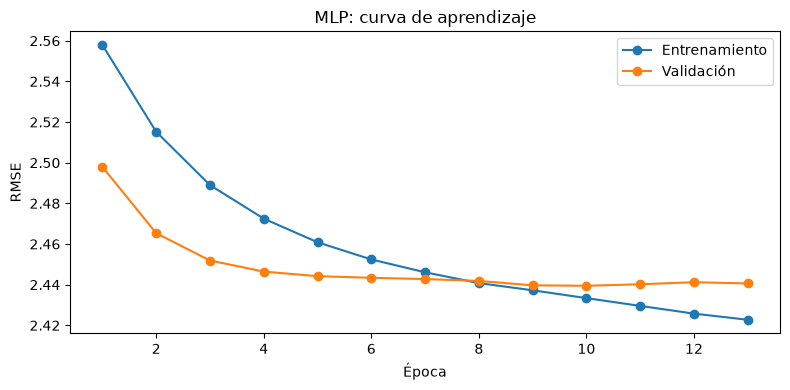

In [6]:
mlp, historial = M.entrenar_mlp(train, capas=(64, 32), lr=1e-3, batch=2048,
                                epocas=MLP_EPOCAS, max_filas=MLP_FILAS)
preds["MLP"] = mlp.predict(test)
print({k: round(v, 3) for k, v in M.metricas(y_test, preds["MLP"]).items()})

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(historial["epoca"], historial["RMSE_train"], marker="o", label="Entrenamiento")
ax.plot(historial["epoca"], historial["RMSE_val"], marker="o", label="Validación")
ax.set_title("MLP: curva de aprendizaje")
ax.set_xlabel("Época")
ax.set_ylabel("RMSE")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/11_curva_aprendizaje_mlp.png", dpi=150)
plt.show()

## 6. XGBoost global

Un solo modelo para las 677 estaciones, con la estación como variable categórica; no necesita escalar las variables. **Hiperparámetros** (búsqueda aleatoria, evaluada en el último 20 % de los días de train, nunca en test):

| Hiperparámetro | Valores probados |
| --- | --- |
| `learning_rate` | 0.03, 0.05, 0.1, 0.2 |
| `max_depth` | 4, 6, 8, 10 |
| `subsample` | 0.6, 0.8, 1.0 |
| `colsample_bytree` | 0.6, 0.8, 1.0 |
| `min_child_weight` | 1, 5, 20 |
| `objective` | error cuadrático o Poisson (las salidas son conteos) |
| `n_estimators` | hasta 1000, con *early stopping* (30 rondas) |

Se usa búsqueda aleatoria y no en malla porque con millones de filas probar todas las combinaciones sería demasiado lento.

In [7]:
busqueda = M.buscar_hiperparametros(train, n_iter=N_ITER)
busqueda

[1/12] RMSE val=2.450  MAE val=1.439  {'subsample': 0.6, 'objective': 'reg:squarederror', 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
[2/12] RMSE val=2.486  MAE val=1.459  {'subsample': 0.6, 'objective': 'reg:squarederror', 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
[3/12] RMSE val=2.444  MAE val=1.426  {'subsample': 1.0, 'objective': 'count:poisson', 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
[4/12] RMSE val=2.461  MAE val=1.433  {'subsample': 0.6, 'objective': 'count:poisson', 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
[5/12] RMSE val=2.462  MAE val=1.432  {'subsample': 1.0, 'objective': 'count:poisson', 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
[6/12] RMSE val=2.484  MAE val=1.444  {'subsample': 1.0, 'objective': 'count:poisson', 'min_child_weight': 5, 'max_depth': 4

,subsample,objective,min_child_weight,max_depth,learning_rate,colsample_bytree,mejor_iteracion,RMSE,MAE,Sesgo
0,1.0,count:poisson,20,8,0.10,0.8,374,2.439716,1.419352,0.144883
1,1.0,count:poisson,1,10,0.03,1.0,711,2.444427,1.425695,0.165566
2,0.6,reg:squarederror,1,10,0.10,0.6,52,2.449640,1.439049,0.138600
3,0.6,count:poisson,20,6,0.05,0.8,1000,2.452017,1.427766,0.121604
4,0.8,count:poisson,1,10,0.10,1.0,208,2.452863,1.428504,0.160986
5,0.8,reg:squarederror,20,8,0.03,1.0,359,2.455094,1.433867,0.145747
6,0.6,count:poisson,1,6,0.03,0.8,1000,2.461267,1.432996,0.096954
7,1.0,count:poisson,1,6,0.03,0.6,1000,2.461680,1.431702,0.093276
8,1.0,count:poisson,20,4,0.03,1.0,1000,2.478760,1.440457,0.056491
9,1.0,count:poisson,5,4,0.03,0.8,1000,2.484415,1.443809,0.053661


In [8]:
mejor = busqueda.iloc[0]
params = {}
for k in M.ESPACIO_BUSQUEDA:
    v = mejor[k]
    params[k] = v if k == "objective" else (int(v) if k in ("max_depth", "min_child_weight") else float(v))
n_arboles = int(mejor["mejor_iteracion"])
print("Mejores hiperparámetros:", params, "| árboles:", n_arboles)

modelo = M.entrenar_xgb(train, params, n_arboles)
preds["XGBoost"] = np.clip(modelo.predict(test[M.FEATURES]), 0, None)
print({k: round(v, 3) for k, v in M.metricas(y_test, preds["XGBoost"]).items()})

Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 8, 'subsample': 1.0, 'colsample_bytree': 0.8, 'min_child_weight': 20, 'objective': 'count:poisson'} | árboles: 374
{'RMSE': 2.37, 'MAE': 1.383, 'Sesgo': 0.06}


## 7. Comparación de modelos

In [9]:
resultados = pd.DataFrame({k: M.metricas(y_test, v) for k, v in preds.items()}).T
ref = resultados.loc["Promedio histórico"]
resultados["Mejora RMSE vs promedio histórico"] = 1 - resultados["RMSE"] / ref["RMSE"]
resultados["Mejora MAE vs promedio histórico"] = 1 - resultados["MAE"] / ref["MAE"]
resultados = resultados.sort_values("RMSE")
mejor_modelo = resultados.drop(index=["Promedio histórico", "Semana pasada", "Media 4 semanas"]).index[0]
print(f"Mejor modelo entrenado (menor RMSE): {mejor_modelo}")
resultados.round(3)

Mejor modelo entrenado (menor RMSE): XGBoost


,RMSE,MAE,Sesgo,Mejora RMSE vs promedio histórico,Mejora MAE vs promedio histórico
XGBoost,2.370,1.383,0.060,0.074,0.045
MLP,2.419,1.396,0.040,0.055,0.036
Regresión lineal,2.453,1.466,0.043,0.042,-0.013
Media 4 semanas,2.494,1.449,-0.028,0.026,-0.001
Promedio histórico,2.559,1.448,0.171,0.000,0.000
Semana pasada,3.055,1.747,-0.019,-0.194,-0.207


In [10]:
# Sobreajuste: error en una muestra de train contra error en prueba
muestra = train.sample(min(300_000, len(train)), random_state=0)
y_m = muestra[M.TARGET].to_numpy()
modelos = {"Regresión lineal": lineal, "MLP": mlp,
           "XGBoost": type("W", (), {"predict": lambda self, d: np.clip(modelo.predict(d[M.FEATURES]), 0, None)})()}
filas = {}
for nombre, m in modelos.items():
    filas[nombre] = {"RMSE train": M.metricas(y_m, m.predict(muestra))["RMSE"],
                     "RMSE prueba": M.metricas(y_test, preds[nombre])["RMSE"]}
sobre = pd.DataFrame(filas).T
sobre["Diferencia"] = sobre["RMSE prueba"] - sobre["RMSE train"]
sobre.round(3)

,RMSE train,RMSE prueba,Diferencia
Regresión lineal,2.645,2.453,-0.193
MLP,2.486,2.419,-0.067
XGBoost,2.385,2.370,-0.016


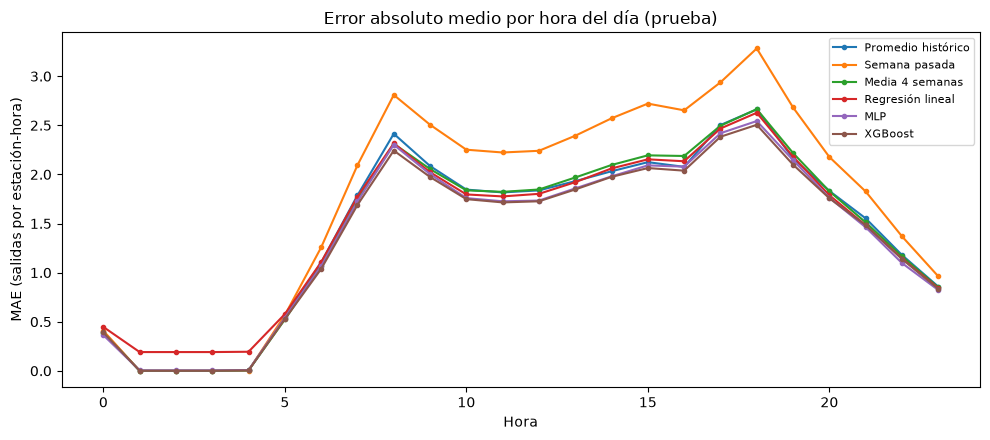

In [11]:
# Error por hora del día (MAE), todos los modelos
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre, p in preds.items():
    e = M.error_por(test, p, "hora")
    ax.plot(e.index, e["MAE"], marker="o", markersize=3, label=nombre)
ax.set_title("Error absoluto medio por hora del día (prueba)")
ax.set_xlabel("Hora")
ax.set_ylabel("MAE (salidas por estación-hora)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("../figures/09_error_por_hora.png", dpi=150)
plt.show()

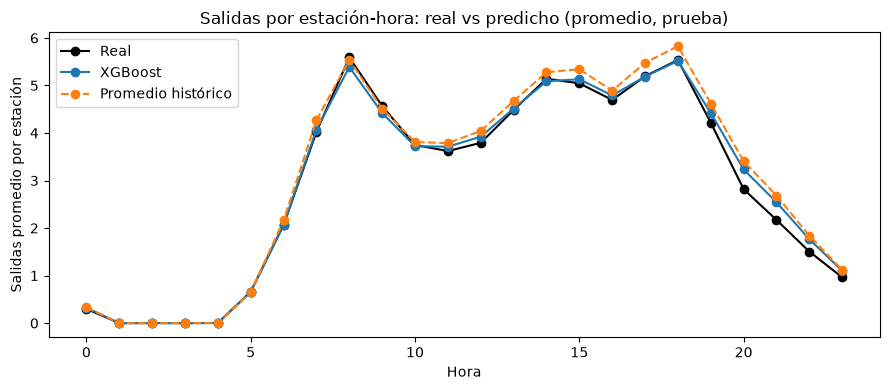

In [12]:
# Real vs predicho: promedio por hora en el periodo de prueba
d = test[["hora"]].copy()
d["Real"] = y_test
for nombre in ["Promedio histórico", mejor_modelo]:
    d[nombre] = preds[nombre]
por_hora = d.groupby("hora").mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(por_hora.index, por_hora["Real"], marker="o", color="black", label="Real")
ax.plot(por_hora.index, por_hora[mejor_modelo], marker="o", label=mejor_modelo)
ax.plot(por_hora.index, por_hora["Promedio histórico"], marker="o", linestyle="--", label="Promedio histórico")
ax.set_title("Salidas por estación-hora: real vs predicho (promedio, prueba)")
ax.set_xlabel("Hora")
ax.set_ylabel("Salidas promedio por estación")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/08_real_vs_predicho.png", dpi=150)
plt.show()

In [13]:
# Error por alcaldía y estaciones con más error, del mejor modelo
p_mejor = preds[mejor_modelo]
display(M.error_por(test, p_mejor, "alcaldia").sort_values("MAE", ascending=False).round(3))

por_est = M.error_por(test, p_mejor, "estacion").sort_values("MAE", ascending=False)
print("10 estaciones con más error (MAE):")
por_est.head(10).round(3)

,RMSE,MAE,n
alcaldia,,,
Cuauhtémoc,2.933,1.713,203280
Miguel Hidalgo,2.488,1.448,116760
Benito Juárez,1.803,1.160,178920
Álvaro Obregón,1.669,0.923,14280
Azcapotzalco,1.323,0.883,23520
Coyoacán,1.287,0.841,30240
desconocido,0.118,0.026,72


10 estaciones con más error (MAE):


,RMSE,MAE,n
estacion,,,
271-272,13.764,6.634,840
548,5.999,3.964,840
237-238,6.426,3.859,840
14,6.631,3.683,840
43,5.878,3.602,840
273-274,8.873,3.569,840
27,5.736,3.499,840
192-193,6.258,3.375,840
194,5.838,3.264,840


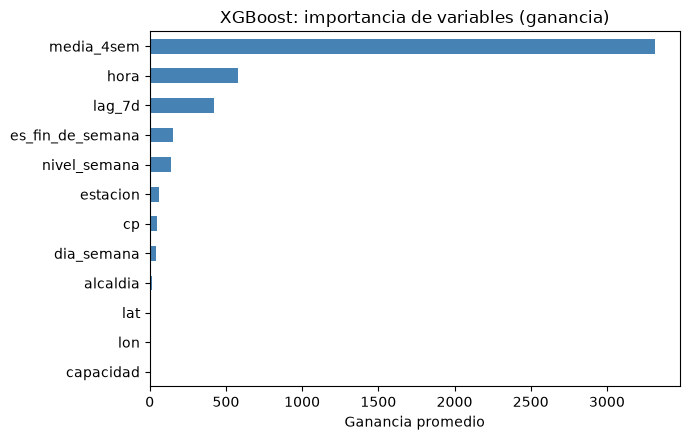

In [14]:
# Importancia de variables de XGBoost (ganancia promedio)
imp = pd.Series(modelo.get_booster().get_score(importance_type="gain")).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
imp.plot.barh(ax=ax, color="steelblue")
ax.set_title("XGBoost: importancia de variables (ganancia)")
ax.set_xlabel("Ganancia promedio")
plt.tight_layout()
plt.savefig("../figures/10_importancia_variables.png", dpi=150)
plt.show()

In [15]:
# Guarda las métricas para el reporte y las slides
sufijo = "_rapido" if RAPIDO else ""
resultados.round(4).to_csv(f"../data/processed/resultados_modelo{sufijo}.csv")
sobre.round(4).to_csv(f"../data/processed/sobreajuste_modelo{sufijo}.csv")
busqueda.round(4).to_csv(f"../data/processed/busqueda_hiperparametros{sufijo}.csv", index=False)
print("Guardado. RAPIDO =", RAPIDO)

Guardado. RAPIDO = False


## 8. Discusión (completar con los resultados de la corrida final)

- **¿Qué modelo ganó y por cuánto?** Tabla de la sección 7: RMSE, MAE y sesgo. ¿Superan los modelos a las referencias simples, en particular a "Media 4 semanas"?
- **Sesgo.** ¿Alguno predice de más o de menos en el periodo de prueba (verano)? ¿Lo corrigen las variables de rezago?
- **Sobreajuste.** Curva del MLP y tabla de train contra prueba.
- **Dónde falla.** Horas pico (figura 09), alcaldías y estaciones con más error (por ejemplo `271-272`, en la zona de Buenavista).
- **Variables.** Importancia en XGBoost (figura 10).
- **Limitaciones.** Seis meses de datos, sin clima ni festivos, estaciones pareadas que suman dos estaciones físicas, y demanda observada (si una estación está vacía no registra salidas).
- **Mejoras.** Clima, festivos, cercanía a Metro y Metrobús, más meses de datos, modelo por tipo de estación.